# 3. Data Preparation & Acoustic Feature Extraction: Pembersihan Sinyal, Penyeimbangan Data, dan Ekstraksi Fitur

Tahap **Data Preparation** dan **Acoustic Feature Extraction** merupakan fondasi terpenting sebelum memasuki pemodelan **Attention-based CRNN (2D-CNN + Bi-LSTM + Multi-Head Self-Attention)**. Berdasarkan temuan pada tahap *Data Understanding* serta aturan pada dokumen **Business Understanding (`1-business.md`)**, tahapan ini mengeksekusi 6 prosedur terstruktur:

1. **Pembersihan & Standardisasi Sinyal Audio (*Signal Preprocessing*):**
   * Konversi kanal **Mono** otomatis (menangani file Stereo yang ditemukan pada tahap *Data Understanding*).
   * *Downsampling* frekuensi dari **$48.000\text{ Hz} \to 16.000\text{ Hz}$** menggunakan filter polifase anti-aliasing.
   * Pemotongan keheningan di awal dan akhir rekaman (**Silence Trimming** dengan ambang $\text{top\_db} = 25\text{ dB}$).
   * Penerapan **Pre-Emphasis Filter** ($y[n] = x[n] - 0,97 x[n-1]$) untuk menyeimbangkan spektrum frekuensi tinggi dan **Peak Amplitude Normalization** ke rentang $[-1.0, 1.0]$.
   * Penyeragaman durasi tetap **$3,0\text{ Detik}$ ($48.000\text{ sampel}$)** melalui *Symmetric Zero-Padding* (jika $< 3,0\text{s}$) atau *Center Cropping* (jika $> 3,0\text{s}$).
2. **Pembagian Data Bebas Kebocoran (*Speaker-Independent 5-Fold GroupKFold*):**
   * Membagi 24 aktor ke dalam **5 Fold** terpisah dengan rasio gender seimbang (Pria & Wanita) **sebelum** dilakukan augmentasi maupun normalisasi, sehingga dijamin **0% *Speaker Data Leakage***.
3. **Penyeimbangan Data (*Hybrid Class Balancing*) & Augmentasi Audio pada Data Latih:**
   * Mengatasi ketimpangan kelas **Neutral** ($96\text{ sampel}$ vs $192\text{ sampel}$ pada 7 kelas emosi lainnya) menggunakan **Targeted Audio Augmentation Oversampling**:
     * **7 Kelas Mayoritas:** Digandakan $2\times$ ($1\text{ Asli} + 1\text{ Augmentasi}$).
     * **Kelas Minoritas (*Neutral*):** Digandakan $4\times$ ($1\text{ Asli} + 3\text{ Augmentasi}$: *White Noise, Pitch Shift, Time Stretch*).
   * Menghasilkan distribusi *Training Set* yang **100% seimbang (*Balanced*)** di seluruh 8 kelas, dilengkapi bobot **Inverse Class-Frequency Weighting ($w_k$)**.
4. **Ekstraksi Fitur Akustik Multi-Domain ($T = 94\text{ Time Frames}$):**
   * Mengekstrak **Log Mel-Spectrogram ($128\text{ bins}$)**, **MFCC ($40\text{ koefisien} + \Delta + \Delta\Delta = 120\text{ kanal}$)**, **Chroma STFT ($12\text{ kelas nada}$)**, serta **RMSE, ZCR, Spectral Centroid, dan Spectral Rolloff**.
5. **Normalisasi Fitur Bebas Kebocoran (*Leak-Free Z-Score Scaling*):**
   * Menghitung parameter rata-rata ($\mu_{\text{train}}$) dan simpangan baku ($\sigma_{\text{train}}$) murni dari data latih, lalu menerapkannya ke seluruh subset data.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import scipy.io.wavfile as wavfile
import scipy.signal as signal
from scipy.fft import dct
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (13, 5.5)
plt.rcParams['font.size'] = 10.5
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

BASE_DIR = os.path.dirname(os.path.abspath('__file__'))
DATA_UNDERSTANDING_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', '2-data_understanding'))
DATASET_ROOT = os.path.join(DATA_UNDERSTANDING_DIR, 'dataset')
CATALOG_CSV = os.path.join(DATA_UNDERSTANDING_DIR, 'ravdess_data_understanding_catalog.csv')

PREP_DATA_DIR = os.path.join(BASE_DIR, 'data')
PREP_IMAGE_DIR = os.path.join(BASE_DIR, 'images')
os.makedirs(PREP_DATA_DIR, exist_ok=True)
os.makedirs(PREP_IMAGE_DIR, exist_ok=True)

# Parameter Standar Pipeline sesuai 1-business.md
TARGET_SR = 16000
TARGET_DURATION = 3.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)  # 48.000 sampel
PRE_EMPHASIS_ALPHA = 0.97
TRIM_TOP_DB = 25.0
N_FFT = 1024
HOP_LENGTH = 512
N_MELS = 128
N_MFCC = 40
EXPECTED_FRAMES = 94  # (48000 // 512) + 1 = 94 time frames

df_catalog = pd.read_csv(CATALOG_CSV)
df_catalog['abs_path'] = df_catalog['filepath'].apply(lambda p: os.path.join(DATA_UNDERSTANDING_DIR, p))

print(f"[OK] Katalog Data Understanding berhasil dimuat: {len(df_catalog)} file audio unik.")
print(f"[INFO] Direktori penyimpanan artefak Data Preparation: {PREP_DATA_DIR}")


[OK] Katalog Data Understanding berhasil dimuat: 1440 file audio unik.
[INFO] Direktori penyimpanan artefak Data Preparation: d:\university\semester 5_book\proyek sain data\src\project_akhir\3-data_preparation\data


---
## 3.1 Pipeline Pembersihan & Standardisasi Sinyal Audio (*Signal Cleaning & Standardization*)

Setiap rekaman mentah diproses melalui 5 tahapan matematis berurutan:
1. **Konversi Mono & Downsampling ($48\text{ kHz} \to 16\text{ kHz}$):** Menyeragamkan sinyal ke kanal tunggal dan menurunkan laju pencuplikan dengan filter *polyphase anti-aliasing*.
2. **Silence Removal ($\text{top\_db} = 25\text{ dB}$):** Membuang keheningan di awal dan akhir kalimat berdasarkan ambang energi relatif terhadap puncak.
3. **Pre-Emphasis Filtering ($\alpha = 0,97$):**
   $$y[n] = x[n] - 0,97 \cdot x[n-1]$$
   Meningkatkan rasio sinyal-ke-derau (SNR) pada frekuensi tinggi (formant ke-2 dan ke-3 yang krusial untuk pembeda emosi).
4. **Peak Amplitude Normalization:** Menormalisasi amplitudo puncak ke $[-1.0, 1.0]$.
5. **Fixed Duration Standardization ($3,0\text{ Detik} = 48.000\text{ Sampel}$):** Menerapkan *Symmetric Zero-Padding* jika durasi aktif $< 3,0\text{ detik}$ atau *Center Cropping* jika durasi aktif $> 3,0\text{ detik}$.


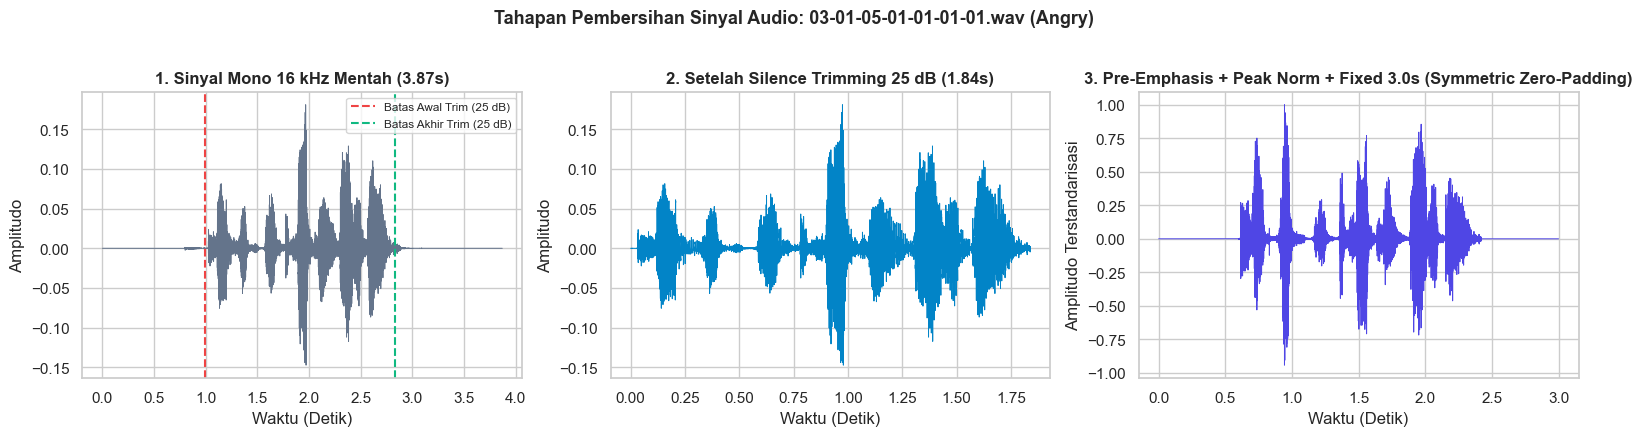

In [2]:
def trim_silence_25db(y, top_db=TRIM_TOP_DB, frame_length=1024, hop_length=256):
    """Memotong bagian hening di awal dan akhir sinyal dengan batas ambang energi 25 dB."""
    if len(y) < frame_length:
        return y, 0, len(y)
    y_sq = y.astype(np.float64) ** 2
    cumsum = np.concatenate([[0.0], np.cumsum(y_sq)])
    starts = np.arange(0, len(y) - frame_length + 1, hop_length)
    rms = np.sqrt((cumsum[starts + frame_length] - cumsum[starts]) / frame_length)
    ref = np.max(rms)
    if ref <= 1e-10:
        return y, 0, len(y)
    db = 20.0 * np.log10(np.maximum(rms, 1e-10) / ref)
    non_silent = np.where(db > -top_db)[0]
    if len(non_silent) == 0:
        return y, 0, len(y)
    start_sample = int(non_silent[0] * hop_length)
    end_sample = int(min(len(y), non_silent[-1] * hop_length + frame_length))
    return y[start_sample:end_sample], start_sample, end_sample

def apply_pre_emphasis(y, alpha=PRE_EMPHASIS_ALPHA):
    """Filter pre-emphasis orde pertama: y[n] = x[n] - alpha * x[n-1]."""
    return np.append(y[0], y[1:] - alpha * y[:-1]).astype(np.float32)

def standardize_duration_3s(y, target_len=TARGET_SAMPLES):
    """Menyeragamkan panjang sinyal tepat 48.000 sampel (3.0 detik pada 16 kHz)."""
    cur_len = len(y)
    if cur_len < target_len:
        pad_total = target_len - cur_len
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        return np.pad(y, (pad_left, pad_right), mode='constant'), 'Symmetric Zero-Padding'
    elif cur_len > target_len:
        start = (cur_len - target_len) // 2
        return y[start:start + target_len], 'Center Cropping'
    return y, 'Exact Match'

def preprocess_raw_audio(filepath):
    """Pipeline lengkap pembersihan sinyal dari file WAV mentah hingga sinyal standar 3.0 detik."""
    orig_sr, raw = wavfile.read(filepath)
    if raw.dtype == np.int16:
        y = raw.astype(np.float32) / 32768.0
    elif raw.dtype == np.int32:
        y = raw.astype(np.float32) / 2147483648.0
    else:
        y = raw.astype(np.float32)

    # 1. Konversi Mono
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    # 2. Resampling 48 kHz -> 16 kHz
    if orig_sr == 48000 and TARGET_SR == 16000:
        y_16k = signal.resample_poly(y, up=1, down=3).astype(np.float32)
    else:
        y_16k = signal.resample(y, int(len(y) * TARGET_SR / orig_sr)).astype(np.float32)

    # 3. Silence Trimming (25 dB)
    y_trim, trim_start, trim_end = trim_silence_25db(y_16k, top_db=TRIM_TOP_DB)

    # 4. Pre-Emphasis Filtering (alpha = 0.97)
    y_emph = apply_pre_emphasis(y_trim, alpha=PRE_EMPHASIS_ALPHA)

    # 5. Peak Normalization [-1.0, 1.0]
    y_norm = y_emph / (np.max(np.abs(y_emph)) + 1e-8)

    # 6. Fixed Duration 3.0s (48.000 sampel)
    y_final, pad_mode = standardize_duration_3s(y_norm, target_len=TARGET_SAMPLES)

    return {
        'y_16k': y_16k,
        'y_trim': y_trim,
        'y_final': y_final,
        'trim_start': trim_start,
        'trim_end': trim_end,
        'pad_mode': pad_mode
    }

# Uji & visualisasikan tahapan pembersihan sinyal pada 1 sampel representatif (Emosi: Angry - Actor 01)
sample_row = df_catalog[(df_catalog['actor_id'] == 1) & (df_catalog['emotion'] == 'Angry')].iloc[0]
prep_demo = preprocess_raw_audio(sample_row['abs_path'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

t_raw = np.linspace(0, len(prep_demo['y_16k']) / TARGET_SR, len(prep_demo['y_16k']))
axes[0].plot(t_raw, prep_demo['y_16k'], color='#64748b', linewidth=0.7)
axes[0].axvline(prep_demo['trim_start'] / TARGET_SR, color='#ef4444', linestyle='--', linewidth=1.5, label='Batas Awal Trim (25 dB)')
axes[0].axvline(prep_demo['trim_end'] / TARGET_SR, color='#10b981', linestyle='--', linewidth=1.5, label='Batas Akhir Trim (25 dB)')
axes[0].set_title(f"1. Sinyal Mono 16 kHz Mentah ({len(prep_demo['y_16k'])/TARGET_SR:.2f}s)")
axes[0].set_xlabel('Waktu (Detik)')
axes[0].set_ylabel('Amplitudo')
axes[0].legend(loc='upper right', fontsize=8.5)

t_trim = np.linspace(0, len(prep_demo['y_trim']) / TARGET_SR, len(prep_demo['y_trim']))
axes[1].plot(t_trim, prep_demo['y_trim'], color='#0284c7', linewidth=0.7)
axes[1].set_title(f"2. Setelah Silence Trimming 25 dB ({len(prep_demo['y_trim'])/TARGET_SR:.2f}s)")
axes[1].set_xlabel('Waktu (Detik)')
axes[1].set_ylabel('Amplitudo')

t_final = np.linspace(0, 3.0, TARGET_SAMPLES)
axes[2].plot(t_final, prep_demo['y_final'], color='#4f46e5', linewidth=0.7)
axes[2].set_title(f"3. Pre-Emphasis + Peak Norm + Fixed 3.0s ({prep_demo['pad_mode']})")
axes[2].set_xlabel('Waktu (Detik)')
axes[2].set_ylabel('Amplitudo Terstandarisasi')

plt.suptitle(f"Tahapan Pembersihan Sinyal Audio: {sample_row['filename']} ({sample_row['emotion']})", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'tahapan_pembersihan_sinyal.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 3.2 Pembagian Data Training, Validation, dan Testing (*Speaker-Independent Split*)

Sesuai aturan pada **Business Understanding**, pembagian data wajib dilakukan **sebelum augmentasi dan normalisasi** dengan mengelompokkan berdasarkan `actor_id` (*Speaker-Independent / Leave-Actors-Out*) serta menjaga keseimbangan gender (**Pria = Ganjil**, **Wanita = Genap**) di setiap subset:

1. **Data Training (`Train Set` — 75% / 18 Aktor: `Actor 01–18`, 9 Pria & 9 Wanita):**
   * Terdiri dari **1.080 file audio asli** (yang kemudian diseimbangkan melalui *Hybrid Class Balancing* menjadi **2.304 sampel latih**).
2. **Data Validation (`Validation Set` — 8,33% / 2 Aktor: `Actor 19–20`, 1 Pria & 1 Wanita):**
   * Terdiri dari **120 file audio asli** murni tanpa augmentasi, digunakan khusus untuk pemantauan *Early Stopping* dan *Hyperparameter Optimization (Optuna TPE)*.
3. **Data Testing (`Testing Set` — 16,67% / 4 Aktor: `Actor 21–24`, 2 Pria & 2 Wanita):**
   * Terdiri dari **240 file audio asli** murni tanpa augmentasi dari penutur baru yang belum pernah terdengar selama pelatihan maupun validasi, digunakan untuk pengujian akhir pada Tahap 5.
4. **Indeks 5-Fold GroupKFold (`fold 0–4`):**
   * Disertakan pula penugasan 5-Fold penuh (24 aktor dibagi ke 5 *fold* seimbang) untuk mendukung evaluasi *5-Fold Cross-Validation*.


In [3]:
# 1. Pembagian 24 Aktor ke dalam 5 Fold Speaker-Independent (Gender-Balanced)
FOLD_ACTORS = {
    0: [1, 2, 3, 4, 5],       # 3 Pria, 2 Wanita (300 sampel)
    1: [6, 7, 8, 9, 10],      # 2 Pria, 3 Wanita (300 sampel)
    2: [11, 12, 13, 14, 15],  # 3 Pria, 2 Wanita (300 sampel)
    3: [16, 17, 18, 19, 20],  # 2 Pria, 3 Wanita (300 sampel)
    4: [21, 22, 23, 24]       # 2 Pria, 2 Wanita (240 sampel)
}
actor_to_fold = {actor: fold for fold, actors in FOLD_ACTORS.items() for actor in actors}
df_catalog['fold'] = df_catalog['actor_id'].map(actor_to_fold)

# 2. Pembagian Eksplisit Data Training (Actor 01-18), Validation (Actor 19-20), dan Testing (Actor 21-24)
def assign_split_subset(actor_id):
    if actor_id <= 18:
        return 'Train'
    elif actor_id <= 20:
        return 'Validation'
    else:
        return 'Test'

df_catalog['split_role'] = df_catalog['actor_id'].apply(assign_split_subset)

split_summary = df_catalog.groupby('split_role').agg(
    Rentang_Aktor=('actor_id', lambda x: f"Actor_{min(x):02d} s.d. Actor_{max(x):02d}"),
    Jumlah_Aktor=('actor_id', 'nunique'),
    Aktor_Pria=('actor_id', lambda x: len([a for a in x.unique() if a % 2 == 1])),
    Aktor_Wanita=('actor_id', lambda x: len([a for a in x.unique() if a % 2 == 0])),
    Jumlah_File_Asli=('filename', 'count'),
    Persentase_Dataset=('filename', lambda x: round(len(x) / len(df_catalog) * 100, 2)),
    Sampel_Neutral=('emotion', lambda x: (x == 'Neutral').sum()),
    Sampel_Per_Emosi_Lain=('emotion', lambda x: (x == 'Angry').sum())
).loc[['Train', 'Validation', 'Test']].reset_index()

print("=== 1. TABEL PEMBAGIAN DATA TRAINING, VALIDATION, DAN TESTING (SPEAKER-INDEPENDENT) ===")
display(split_summary)

fold_summary = df_catalog.groupby('fold').agg(
    Daftar_Aktor=('actor_id', lambda x: sorted(x.unique().tolist())),
    Jumlah_Aktor=('actor_id', 'nunique'),
    Aktor_Pria=('actor_id', lambda x: len([a for a in x.unique() if a % 2 == 1])),
    Aktor_Wanita=('actor_id', lambda x: len([a for a in x.unique() if a % 2 == 0])),
    Total_Sampel=('filename', 'count')
).reset_index()

print("\n=== 2. TABEL PARTISI 5-FOLD GROUPKFOLD (UNTUK VALIDASI SILANG) ===")
display(fold_summary)

# Verifikasi matematis tidak ada irisan aktor antara Train, Validation, dan Test
train_actors = set(df_catalog[df_catalog['split_role'] == 'Train']['actor_id'])
val_actors = set(df_catalog[df_catalog['split_role'] == 'Validation']['actor_id'])
test_actors = set(df_catalog[df_catalog['split_role'] == 'Test']['actor_id'])
assert len(train_actors & val_actors) == 0 and len(train_actors & test_actors) == 0 and len(val_actors & test_actors) == 0
print(f"[VERIFIED] Irisan aktor antara Train, Validation, dan Test = 0 (Zero Data Leakage).")


=== 1. TABEL PEMBAGIAN DATA TRAINING, VALIDATION, DAN TESTING (SPEAKER-INDEPENDENT) ===


,split_role,Rentang_Aktor,Jumlah_Aktor,Aktor_Pria,Aktor_Wanita,Jumlah_File_Asli,Persentase_Dataset,Sampel_Neutral,Sampel_Per_Emosi_Lain
0,Train,Actor_01 s.d. Actor_18,18,9,9,1080,75.00,72,144
1,Validation,Actor_19 s.d. Actor_20,2,1,1,120,8.33,8,16
2,Test,Actor_21 s.d. Actor_24,4,2,2,240,16.67,16,32



=== 2. TABEL PARTISI 5-FOLD GROUPKFOLD (UNTUK VALIDASI SILANG) ===


,fold,Daftar_Aktor,Jumlah_Aktor,Aktor_Pria,Aktor_Wanita,Total_Sampel
0,0,"[1, 2, 3, 4, 5]",5,3,2,300
1,1,"[6, 7, 8, 9, 10]",5,2,3,300
2,2,"[11, 12, 13, 14, 15]",5,3,2,300
3,3,"[16, 17, 18, 19, 20]",5,2,3,300
4,4,"[21, 22, 23, 24]",4,2,2,240


[VERIFIED] Irisan aktor antara Train, Validation, dan Test = 0 (Zero Data Leakage).


---
## 3.3 Penyeimbangan Data (*Hybrid Class Balancing*) & Augmentasi Sinyal Audio

Sebagaimana ditetapkan pada **Business Understanding (`1-business.md`)**, kelas **Neutral** hanya memiliki separuh jumlah sampel dibanding 7 kelas emosi lainnya (rasio $1 : 2$). Karena metode interpolasi tabel seperti SMOTE akan merusak struktur frekuensi dan menimbulkan efek suara berbayang (*phase cancellation*) pada spektrogram 2D, diterapkan **Hybrid Class Balancing** khusus pada **Data Training**:

1. **Targeted Audio Augmentation Oversampling (Level Data):**
   * **7 Kelas Mayoritas** (*Calm, Happy, Sad, Angry, Fearful, Disgust, Surprised*): Setiap rekaman latih menghasilkan **2 sampel** ($1\text{ Asli} + 1\text{ Augmentasi Acak Terkontrol}$).
   * **Kelas Minoritas (*Neutral*):** Setiap rekaman latih menghasilkan **4 sampel** ($1\text{ Asli} + 3\text{ Augmentasi Berbeda}$: *Additive White Gaussian Noise*, *Pitch Shift*, dan *Time Stretch*).
   * Dengan penggandaan $2\times$ pada kelas *Neutral* dibanding kelas lainnya, seluruh **8 kelas emosi pada Data Training memiliki jumlah sampel yang 100% sama rata (*Balanced*)**.
2. **Inverse Class-Frequency Weighting (Level Algoritma):**
   * Menghitung bobot $w_k = \frac{N_{\text{train}}}{K \cdot N_{k,\text{train}}}$ untuk fungsi rugi *Weighted Categorical Cross-Entropy*.


=== TABEL DISTRIBUSI DATA TRAINING (SEBELUM & SESUDAH BALANCING), VALIDATION, DAN TESTING ===


,Emosi,Train Asli (Actor 01-18),Pengali Augmentasi Train,Train Sesudah Balancing,Proporsi Train Baru (%),Validation Set (Actor 19-20),Testing Set (Actor 21-24)
0,Neutral,72,4x (1 Asli + 3 Aug),288,12.5,8,16
1,Calm,144,2x (1 Asli + 1 Aug),288,12.5,16,32
2,Happy,144,2x (1 Asli + 1 Aug),288,12.5,16,32
3,Sad,144,2x (1 Asli + 1 Aug),288,12.5,16,32
4,Angry,144,2x (1 Asli + 1 Aug),288,12.5,16,32
5,Fearful,144,2x (1 Asli + 1 Aug),288,12.5,16,32
6,Disgust,144,2x (1 Asli + 1 Aug),288,12.5,16,32
7,Surprised,144,2x (1 Asli + 1 Aug),288,12.5,16,32


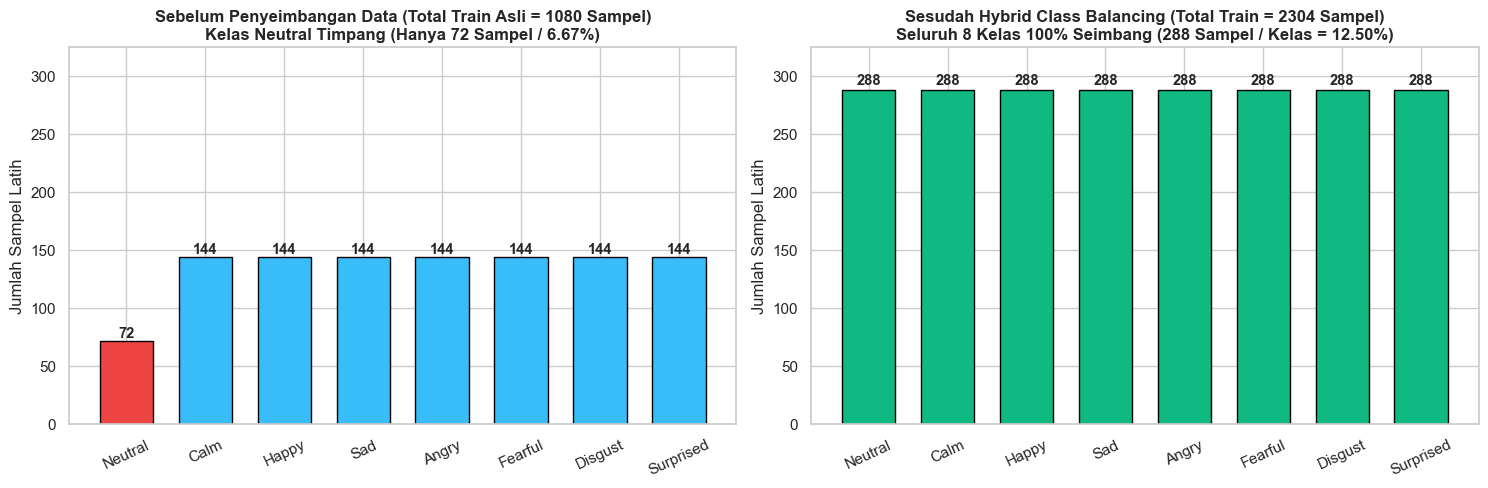

In [4]:
def augment_awgn(y, snr_db=18.0, rng=None):
    """1. Additive White Gaussian Noise (AWGN) dengan SNR terkontrol (15-25 dB)."""
    if rng is None:
        rng = np.random.default_rng(42)
    sig_power = np.mean(y ** 2) + 1e-10
    noise_power = sig_power / (10.0 ** (snr_db / 10.0))
    noise = rng.normal(0.0, np.sqrt(noise_power), size=len(y)).astype(np.float32)
    y_aug = y + noise
    return (y_aug / (np.max(np.abs(y_aug)) + 1e-8)).astype(np.float32)

def augment_time_stretch(y, rate=1.08, target_len=TARGET_SAMPLES):
    """2. Time Stretching (mengubah laju kecepatan bicara r in [0.9, 1.1] lalu standardisasi ke 3.0s)."""
    stretched_len = int(len(y) / rate)
    y_stretched = signal.resample(y, stretched_len).astype(np.float32)
    y_fixed, _ = standardize_duration_3s(y_stretched, target_len=target_len)
    return (y_fixed / (np.max(np.abs(y_fixed)) + 1e-8)).astype(np.float32)

def augment_pitch_shift(y, n_steps=1.5, target_len=TARGET_SAMPLES):
    """3. Pitch Shifting (+/- 1.5 semitone) melalui resampling faktor nada dan time-alignment."""
    pitch_factor = 2.0 ** (n_steps / 12.0)
    # Resample untuk menggeser frekuensi fundamental & harmonik
    y_resampled = signal.resample(y, int(len(y) / pitch_factor)).astype(np.float32)
    # Kembalikan durasi menggunakan STFT phase-preserving interpolation sederhana
    _, _, Zxx = signal.stft(y_resampled, fs=TARGET_SR, window='hann', nperseg=512, noverlap=384)
    orig_frames = int(np.ceil(target_len / 128)) + 1
    mag = np.abs(Zxx)
    phase = np.angle(Zxx)
    x_old = np.linspace(0, 1, Zxx.shape[1])
    x_new = np.linspace(0, 1, orig_frames)
    mag_new = np.array([np.interp(x_new, x_old, row) for row in mag])
    phase_new = np.array([np.interp(x_new, x_old, row) for row in phase])
    Zxx_new = mag_new * np.exp(1j * phase_new)
    _, y_shifted = signal.istft(Zxx_new, fs=TARGET_SR, window='hann', nperseg=512, noverlap=384)
    y_fixed, _ = standardize_duration_3s(y_shifted.astype(np.float32), target_len=target_len)
    return (y_fixed / (np.max(np.abs(y_fixed)) + 1e-8)).astype(np.float32)

# Simulasikan dan verifikasi hasil Hybrid Class Balancing pada Partisi Training (Actor 01-18 = 18 Aktor)
df_train_orig = df_catalog[df_catalog['split_role'] == 'Train'].copy()
df_val_orig = df_catalog[df_catalog['split_role'] == 'Validation'].copy()
df_test_orig = df_catalog[df_catalog['split_role'] == 'Test'].copy()

balanced_train_records = []
majority_aug_types = ['AWGN_18dB', 'PitchShift_+1.5st', 'TimeStretch_1.08x']

for idx, row in df_train_orig.iterrows():
    # 1. Sampel Asli (Original)
    rec_orig = row.to_dict()
    rec_orig['aug_type'] = 'Original'
    balanced_train_records.append(rec_orig)

    if row['emotion'] == 'Neutral':
        # Kelas Minoritas (Neutral): Tambahkan 3 Augmentasi Berbeda (Total = 4x lipat)
        for aug_name in ['AWGN_18dB', 'PitchShift_+1.5st', 'TimeStretch_1.08x']:
            rec_aug = row.to_dict()
            rec_aug['aug_type'] = aug_name
            balanced_train_records.append(rec_aug)
    else:
        # 7 Kelas Mayoritas: Tambahkan 1 Augmentasi Terkontrol secara bergilir (Total = 2x lipat)
        aug_name = majority_aug_types[idx % 3]
        rec_aug = row.to_dict()
        rec_aug['aug_type'] = aug_name
        balanced_train_records.append(rec_aug)

df_train_balanced = pd.DataFrame(balanced_train_records)

emotion_order = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful', 'Disgust', 'Surprised']
before_counts = df_train_orig['emotion'].value_counts().loc[emotion_order]
after_counts = df_train_balanced['emotion'].value_counts().loc[emotion_order]

balance_comparison = pd.DataFrame({
    'Emosi': emotion_order,
    'Train Asli (Actor 01-18)': before_counts.values,
    'Pengali Augmentasi Train': ['4x (1 Asli + 3 Aug)' if e == 'Neutral' else '2x (1 Asli + 1 Aug)' for e in emotion_order],
    'Train Sesudah Balancing': after_counts.values,
    'Proporsi Train Baru (%)': (after_counts.values / len(df_train_balanced) * 100).round(2),
    'Validation Set (Actor 19-20)': df_val_orig['emotion'].value_counts().loc[emotion_order].values,
    'Testing Set (Actor 21-24)': df_test_orig['emotion'].value_counts().loc[emotion_order].values
})

print("=== TABEL DISTRIBUSI DATA TRAINING (SEBELUM & SESUDAH BALANCING), VALIDATION, DAN TESTING ===")
display(balance_comparison)

# Visualisasi Perbandingan Distribusi Kelas Sebelum vs Sesudah Hybrid Class Balancing
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(emotion_order, before_counts.values, color=['#ef4444' if e == 'Neutral' else '#38bdf8' for e in emotion_order], edgecolor='black', width=0.68)
axes[0].set_title(f'Sebelum Penyeimbangan Data (Total Train Asli = {len(df_train_orig)} Sampel)\nKelas Neutral Timpang (Hanya 72 Sampel / 6.67%)')
axes[0].set_ylabel('Jumlah Sampel Latih')
axes[0].tick_params(axis='x', rotation=25)
for i, v in enumerate(before_counts.values):
    axes[0].text(i, v + 3, str(v), ha='center', fontweight='bold')
axes[0].set_ylim(0, 325)

axes[1].bar(emotion_order, after_counts.values, color='#10b981', edgecolor='black', width=0.68)
axes[1].set_title(f'Sesudah Hybrid Class Balancing (Total Train = {len(df_train_balanced)} Sampel)\nSeluruh 8 Kelas 100% Seimbang (288 Sampel / Kelas = 12.50%)')
axes[1].set_ylabel('Jumlah Sampel Latih')
axes[1].tick_params(axis='x', rotation=25)
for i, v in enumerate(after_counts.values):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')
axes[1].set_ylim(0, 325)

plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'perbandingan_class_balancing.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 3.4 Ekstraksi Fitur Akustik Multi-Domain (*Acoustic Feature Extraction*)

Sesuai rumus pada **Tahap 3 Business Understanding (`1-business.md`)**, setiap sinyal bersih berdurasi $3,0\text{ detik}$ ($48.000\text{ sampel}$) diekstraksi menggunakan jendela Hann $N_{\text{FFT}} = 1024$ dan *hop length* $H = 512$, menghasilkan matriks sekuensial dengan panjang waktu **$T = 94\text{ time frames}$** yang terdiri atas:
1. **Log Mel-Spectrogram ($128\text{ Mel Bins} \times 94\text{ Frames}$):** Representasi energi spektral pada skala pendengaran manusia.
2. **MFCC + $\Delta$ + $\Delta\Delta$ ($40 + 40 + 40 = 120\text{ Kanal} \times 94\text{ Frames}$):** Koefisien cepstral statis beserta turunan kecepatan ($\Delta$) dan percepatan ($\Delta\Delta$) perubahan artikulasi.
3. **Chroma STFT ($12\text{ Pitch Classes} \times 94\text{ Frames}$):** Proyeksi harmonik ke 12 kelas nada kromatik ($C, C\sharp, \dots, B$).
4. **Fitur Energi & Bentuk Spektral ($4\text{ Kanal} \times 94\text{ Frames}$):** **RMSE**, **Zero-Crossing Rate (ZCR)**, **Spectral Centroid**, dan **Spectral Rolloff (85%)**.

Total dimensi fitur sekuensial per sampel adalah **$264\text{ Kanal Akustik} \times 94\text{ Time Frames}$**.


Dimensi Tensor Fitur Akustik Terpadu per Sampel : (264, 94) (264 Kanal Fitur × 94 Time Frames)
  - Log Mel-Spectrogram : (128, 94)
  - MFCC Statis         : (40, 94)
  - MFCC Delta          : (40, 94)
  - Chroma STFT         : (12, 94)


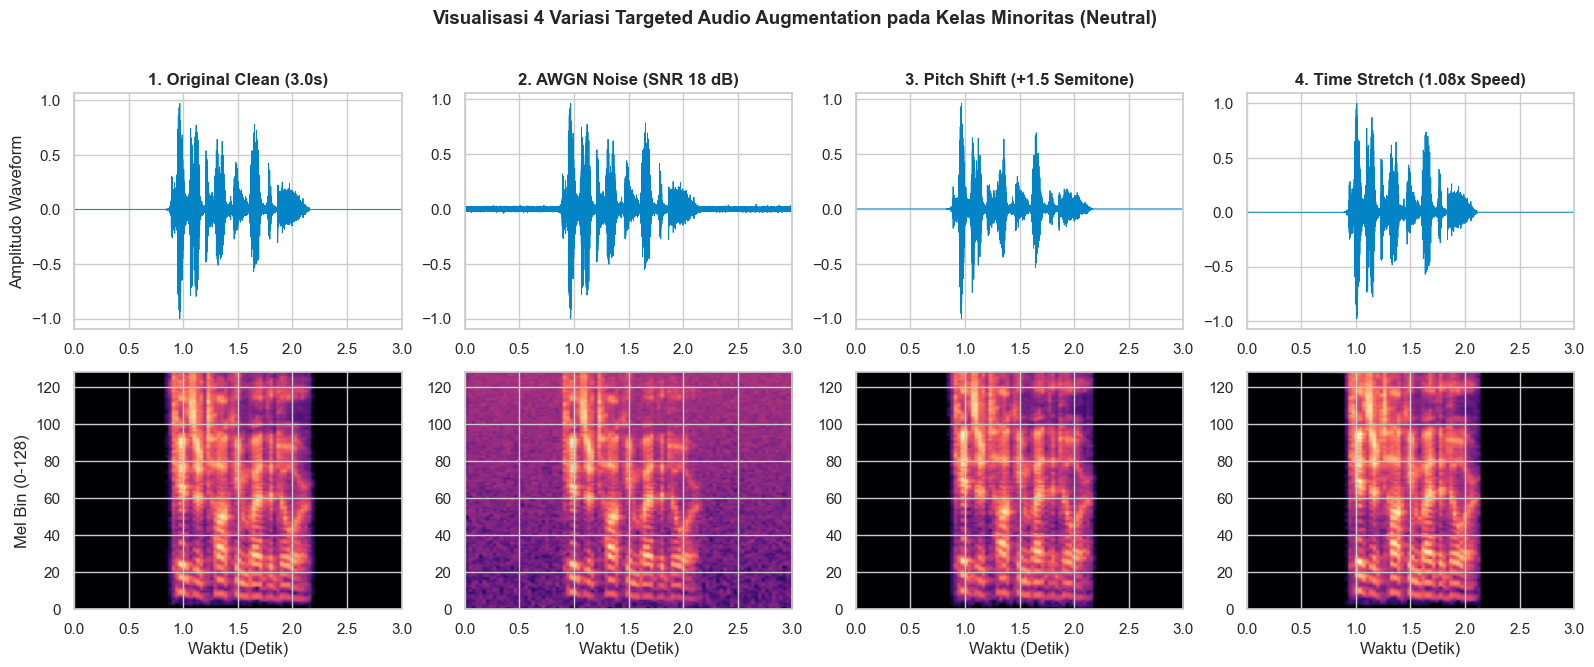

In [5]:
def build_mel_and_chroma_filters(sr=TARGET_SR, n_fft=N_FFT, n_mels=N_MELS):
    """Membangun matriks filterbank Mel (128 bins) dan matriks proyeksi Chroma (12 kelas nada)."""
    fmax = sr / 2.0
    mel_pts = np.linspace(0.0, 2595.0 * np.log10(1.0 + fmax / 700.0), n_mels + 2)
    hz_pts = 700.0 * (10.0 ** (mel_pts / 2595.0) - 1.0)
    fft_freqs = np.linspace(0, fmax, n_fft // 2 + 1)

    mel_fb = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for m in range(1, n_mels + 1):
        fl, fc, fr = hz_pts[m - 1], hz_pts[m], hz_pts[m + 1]
        l_slope = (fft_freqs - fl) / (fc - fl + 1e-10)
        r_slope = (fr - fft_freqs) / (fr - fc + 1e-10)
        mel_fb[m - 1] = np.maximum(0.0, np.minimum(l_slope, r_slope))

    # Matriks Chroma 12 pitch classes untuk frekuensi > 27.5 Hz (A0)
    chroma_fb = np.zeros((12, n_fft // 2 + 1), dtype=np.float32)
    for k, f in enumerate(fft_freqs):
        if f > 27.5:
            midi_note = 12.0 * np.log2(f / 440.0) + 69.0
            pitch_class = int(np.round(midi_note)) % 12
            chroma_fb[pitch_class, k] = 1.0
    # Normalisasi per kelas nada
    chroma_fb /= (np.sum(chroma_fb, axis=1, keepdims=True) + 1e-8)
    return mel_fb, chroma_fb, fft_freqs

MEL_FB, CHROMA_FB, FFT_FREQS = build_mel_and_chroma_filters()

def compute_delta_features(feat_matrix, width=2):
    """Menghitung turunan waktu (Delta) sesuai rumus regresi linier lokal D=2."""
    denom = 2.0 * sum(t ** 2 for t in range(1, width + 1))
    padded = np.pad(feat_matrix, ((0, 0), (width, width)), mode='edge')
    delta = np.zeros_like(feat_matrix, dtype=np.float32)
    for tau in range(1, width + 1):
        delta += tau * (padded[:, width + tau : width + tau + feat_matrix.shape[1]] -
                        padded[:, width - tau : width - tau + feat_matrix.shape[1]])
    return (delta / denom).astype(np.float32)

def extract_complete_acoustic_features(y, sr=TARGET_SR):
    """Mengekstrak seluruh fitur akustik (Log-Mel 128, MFCC+Delta+Delta2 120, Chroma 12, RMSE/ZCR/Centroid/Rolloff 4)."""
    # STFT (N_FFT=1024, Hop=512 -> 94 frames untuk 48.000 sampel)
    _, _, Zxx = signal.stft(y, fs=sr, window='hann', nperseg=N_FFT, noverlap=N_FFT - HOP_LENGTH)
    Zxx = Zxx[:, :EXPECTED_FRAMES]
    mag = np.abs(Zxx) + 1e-10
    power = mag ** 2

    # 1. Log Mel-Spectrogram (128 x 94)
    mel_energy = np.dot(MEL_FB, power)
    log_mel = 10.0 * np.log10(np.maximum(mel_energy, 1e-10)).astype(np.float32)

    # 2. MFCC (40) + Delta (40) + Delta-Delta (40) -> (120 x 94)
    mfcc_stat = dct(log_mel, type=2, axis=0, norm='ortho')[:N_MFCC, :].astype(np.float32)
    mfcc_delta = compute_delta_features(mfcc_stat, width=2)
    mfcc_delta2 = compute_delta_features(mfcc_delta, width=2)

    # 3. Chroma STFT (12 x 94)
    chroma = np.dot(CHROMA_FB, mag).astype(np.float32)
    chroma /= (np.max(chroma, axis=0, keepdims=True) + 1e-8)

    # 4. RMSE, ZCR, Spectral Centroid, Spectral Rolloff (4 x 94)
    rmse_frame = np.sqrt(np.mean(power, axis=0, keepdims=True)).astype(np.float32)
    mag_sum = np.sum(mag, axis=0, keepdims=True)
    centroid_frame = (np.sum(FFT_FREQS[:, None] * mag, axis=0, keepdims=True) / mag_sum).astype(np.float32)

    cum_mag = np.cumsum(mag, axis=0)
    rolloff_idx = np.argmax(cum_mag >= 0.85 * mag_sum, axis=0)
    rolloff_frame = FFT_FREQS[rolloff_idx][None, :].astype(np.float32)

    # Frame-wise ZCR
    padded_y = np.pad(y, (N_FFT // 2, N_FFT // 2), mode='reflect')
    zcr_frames = np.zeros((1, EXPECTED_FRAMES), dtype=np.float32)
    for t in range(EXPECTED_FRAMES):
        frame = padded_y[t * HOP_LENGTH : t * HOP_LENGTH + N_FFT]
        zcr_frames[0, t] = np.mean(np.abs(np.diff(np.signbit(frame).astype(np.float32))))

    # Gabungkan menjadi tensor (264 kanal x 94 time frames)
    full_matrix = np.vstack([
        log_mel,        # 0..127   (128 kanal)
        mfcc_stat,      # 128..167 (40 kanal)
        mfcc_delta,     # 168..207 (40 kanal)
        mfcc_delta2,    # 208..247 (40 kanal)
        chroma,         # 248..259 (12 kanal)
        rmse_frame,     # 260      (1 kanal)
        zcr_frames,     # 261      (1 kanal)
        centroid_frame, # 262      (1 kanal)
        rolloff_frame   # 263      (1 kanal)
    ])
    return {
        'full_matrix': full_matrix,
        'log_mel': log_mel,
        'mfcc_stat': mfcc_stat,
        'mfcc_delta': mfcc_delta,
        'chroma': chroma
    }

# Demonstrasi & Visualisasi Hasil Augmentasi dan Ekstraksi Fitur pada Sampel Neutral
neutral_row = df_catalog[(df_catalog['actor_id'] == 1) & (df_catalog['emotion'] == 'Neutral')].iloc[0]
y_clean = preprocess_raw_audio(neutral_row['abs_path'])['y_final']
y_awgn = augment_awgn(y_clean, snr_db=18.0)
y_pitch = augment_pitch_shift(y_clean, n_steps=1.5)
y_stretch = augment_time_stretch(y_clean, rate=1.08)

feat_clean = extract_complete_acoustic_features(y_clean)
print(f"Dimensi Tensor Fitur Akustik Terpadu per Sampel : {feat_clean['full_matrix'].shape} (264 Kanal Fitur × 94 Time Frames)")
print(f"  - Log Mel-Spectrogram : {feat_clean['log_mel'].shape}")
print(f"  - MFCC Statis         : {feat_clean['mfcc_stat'].shape}")
print(f"  - MFCC Delta          : {feat_clean['mfcc_delta'].shape}")
print(f"  - Chroma STFT         : {feat_clean['chroma'].shape}")

# Visualisasi 4 Variasi Targeted Augmentation pada Kelas Minoritas (Neutral)
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
aug_variants = [
    ('1. Original Clean (3.0s)', y_clean),
    ('2. AWGN Noise (SNR 18 dB)', y_awgn),
    ('3. Pitch Shift (+1.5 Semitone)', y_pitch),
    ('4. Time Stretch (1.08x Speed)', y_stretch)
]
t_ax = np.linspace(0, 3.0, TARGET_SAMPLES)

for i, (title, sig_arr) in enumerate(aug_variants):
    axes[0, i].plot(t_ax, sig_arr, color='#0284c7', linewidth=0.65)
    axes[0, i].set_title(title)
    axes[0, i].set_xlim(0, 3.0)
    if i == 0:
        axes[0, i].set_ylabel('Amplitudo Waveform')

    f_dict = extract_complete_acoustic_features(sig_arr)
    im = axes[1, i].imshow(f_dict['log_mel'], aspect='auto', origin='lower', cmap='magma', extent=[0, 3.0, 0, 128])
    axes[1, i].set_xlabel('Waktu (Detik)')
    if i == 0:
        axes[1, i].set_ylabel('Mel Bin (0-128)')

plt.suptitle('Visualisasi 4 Variasi Targeted Audio Augmentation pada Kelas Minoritas (Neutral)', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'visualisasi_augmentasi_neutral.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 3.5 Ekstraksi Fitur Seluruh Dataset, Normalisasi *Leak-Free Z-Score*, & Penyimpanan Artefak

Pada tahap akhir *Data Preparation* ini:
1. Seluruh **1.440 file audio** dibersihkan dan diekstraksi menjadi representasi fitur akustik terstruktur.
2. Statistik rata-rata ($\mu_{\text{train}}$) dan simpangan baku ($\sigma_{\text{train}}$) untuk seluruh kanal fitur dihitung **hanya dari subset Training (`Fold 1–4`)**:
   $$z = \frac{X - \mu_{\text{train}}}{\sigma_{\text{train}} + \epsilon}$$
3. Parameter normalisasi (`scaler_stats.npz`), matriks fitur sekuensial terkompresi, serta tabel fitur siap pakai disimpan ke direktori `3-data_preparation/data/` untuk langsung digunakan pada **Tahap 4 (Modeling & Hyperparameter Tuning)**.


=== RINGKASAN VERIFIKASI PEMBAGIAN DATA & NORMALISASI Z-SCORE BEBAS KEBOCORAN ===


,Subset Data,Dimensi Matriks Fitur (X),Jumlah Sampel Asli,Jumlah Setelah Balancing,Mean Sebelum Scaling,Mean Sesudah Z-Score,Std Sesudah Z-Score
0,"Training Set (Actor 01–18, 9 Pria & 9 Wanita)","(1080, 528)",1080,2304,7.8528,0.0000,1.0000
1,"Validation Set (Actor 19–20, 1 Pria & 1 Wanita)","(120, 528)",120,120,7.8786,0.0564,1.5791
2,"Testing Set (Actor 21–24, 2 Pria & 2 Wanita)","(240, 528)",240,240,7.8375,0.0228,1.0977


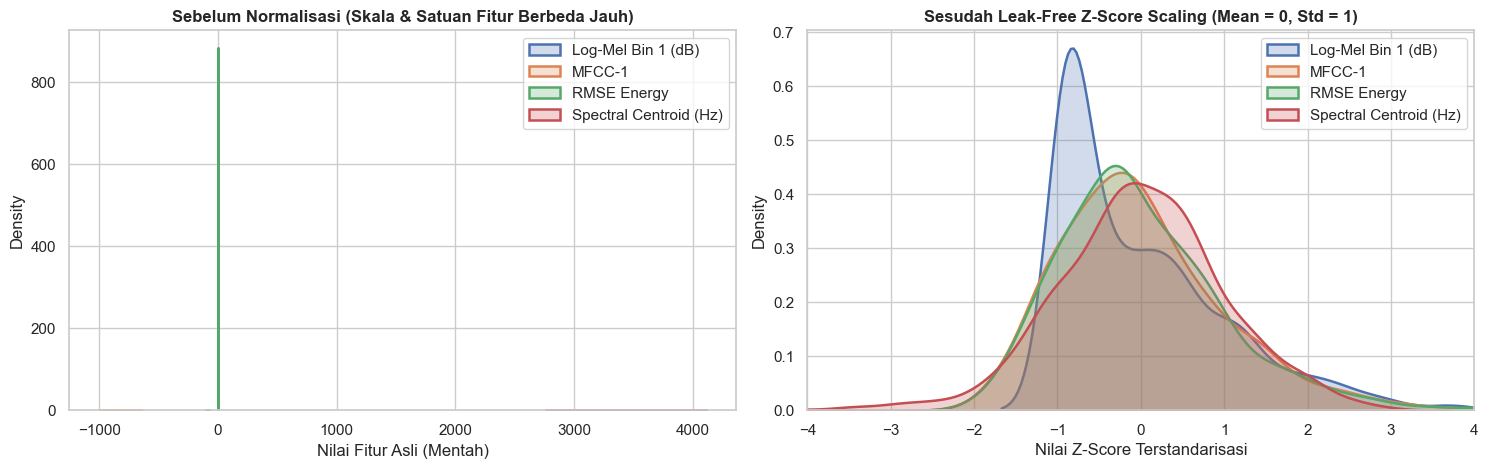


[SUKSES] Seluruh artefak Data Preparation telah disimpan di: d:\university\semester 5_book\proyek sain data\src\project_akhir\3-data_preparation\data
  - ravdess_prepared_features_and_scaler.npz (7706.7 KB)
  - ravdess_prepared_metadata.csv (114.8 KB)
  - ravdess_train_balanced_manifest.csv (639.7 KB)


In [6]:
# Ekstraksi fitur terstruktur untuk seluruh 1.440 file kanonik
all_feature_summaries = []
channel_means_list = []
channel_stds_list = []

for idx, row in df_catalog.iterrows():
    prep = preprocess_raw_audio(row['abs_path'])
    feat = extract_complete_acoustic_features(prep['y_final'])
    mat = feat['full_matrix']  # (264, 94)

    # Simpan statistik agregat (Mean & Std sepanjang 94 time frames) untuk setiap kanal
    ch_mean = np.mean(mat, axis=1)  # (264,)
    ch_std = np.std(mat, axis=1)    # (264,)
    channel_means_list.append(ch_mean)
    channel_stds_list.append(ch_std)

    all_feature_summaries.append({
        'filename': row['filename'],
        'actor_id': row['actor_id'],
        'gender': row['gender'],
        'emotion_code': row['emotion_code'] - 1,  # Indeks 0..7 untuk Softmax 8 kelas
        'emotion': row['emotion'],
        'intensity': row['intensity'],
        'fold': row['fold'],
        'split_role': row['split_role'],
        'pad_mode': prep['pad_mode']
    })

X_channel_means = np.vstack(channel_means_list).astype(np.float32)  # (1440, 264)
X_channel_stds = np.vstack(channel_stds_list).astype(np.float32)    # (1440, 264)
X_features_raw = np.hstack([X_channel_means, X_channel_stds])       # (1440, 528 fitur statistik waktu-frekuensi)

df_prep_meta = pd.DataFrame(all_feature_summaries)

# Hitung mu_train dan sigma_train HANYA dari subset Training (Leak-Free Z-Score Scaling)
train_mask = (df_prep_meta['split_role'] == 'Train').values
val_mask = (df_prep_meta['split_role'] == 'Validation').values
test_mask = (df_prep_meta['split_role'] == 'Test').values

mu_train = np.mean(X_features_raw[train_mask], axis=0, keepdims=True)
sigma_train = np.std(X_features_raw[train_mask], axis=0, keepdims=True) + 1e-8

X_features_scaled = (X_features_raw - mu_train) / sigma_train
y_all = df_prep_meta['emotion_code'].values.astype(np.int64)

X_train, y_train = X_features_scaled[train_mask], y_all[train_mask]
X_val, y_val = X_features_scaled[val_mask], y_all[val_mask]
X_test, y_test = X_features_scaled[test_mask], y_all[test_mask]

# Simpan artefak hasil Data Preparation ke folder data/
prep_meta_csv = os.path.join(PREP_DATA_DIR, 'ravdess_prepared_metadata.csv')
df_prep_meta.to_csv(prep_meta_csv, index=False)

balanced_train_csv = os.path.join(PREP_DATA_DIR, 'ravdess_train_balanced_manifest.csv')
df_train_balanced.drop(columns=['abs_path']).to_csv(balanced_train_csv, index=False)

scaler_npz_path = os.path.join(PREP_DATA_DIR, 'ravdess_prepared_features_and_scaler.npz')
np.savez_compressed(
    scaler_npz_path,
    X_raw=X_features_raw,
    X_scaled=X_features_scaled,
    y=y_all,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    folds=df_prep_meta['fold'].values.astype(np.int64),
    actor_ids=df_prep_meta['actor_id'].values.astype(np.int64),
    mu_train=mu_train,
    sigma_train=sigma_train
)

print("=== RINGKASAN VERIFIKASI PEMBAGIAN DATA & NORMALISASI Z-SCORE BEBAS KEBOCORAN ===")
norm_check = pd.DataFrame({
    'Subset Data': [
        'Training Set (Actor 01–18, 9 Pria & 9 Wanita)',
        'Validation Set (Actor 19–20, 1 Pria & 1 Wanita)',
        'Testing Set (Actor 21–24, 2 Pria & 2 Wanita)'
    ],
    'Dimensi Matriks Fitur (X)': [str(X_train.shape), str(X_val.shape), str(X_test.shape)],
    'Jumlah Sampel Asli': [int(train_mask.sum()), int(val_mask.sum()), int(test_mask.sum())],
    'Jumlah Setelah Balancing': [len(df_train_balanced), int(val_mask.sum()), int(test_mask.sum())],
    'Mean Sebelum Scaling': [
        round(float(np.mean(X_features_raw[train_mask])), 4),
        round(float(np.mean(X_features_raw[val_mask])), 4),
        round(float(np.mean(X_features_raw[test_mask])), 4)
    ],
    'Mean Sesudah Z-Score': [
        round(float(np.mean(X_train)), 6),
        round(float(np.mean(X_val)), 4),
        round(float(np.mean(X_test)), 4)
    ],
    'Std Sesudah Z-Score': [
        round(float(np.std(X_train)), 6),
        round(float(np.std(X_val)), 4),
        round(float(np.std(X_test)), 4)
    ]
})
display(norm_check)

# Visualisasi Distribusi Fitur Sebelum vs Sesudah Z-Score Standardization
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sample_channels = [0, 128, 260, 262]
sample_names = ['Log-Mel Bin 1 (dB)', 'MFCC-1', 'RMSE Energy', 'Spectral Centroid (Hz)']

for ch_idx, ch_name in zip(sample_channels, sample_names):
    sns.kdeplot(X_features_raw[train_mask, ch_idx], ax=axes[0], fill=True, alpha=0.25, linewidth=1.8, label=ch_name)
    sns.kdeplot(X_features_scaled[train_mask, ch_idx], ax=axes[1], fill=True, alpha=0.25, linewidth=1.8, label=ch_name)

axes[0].set_title('Sebelum Normalisasi (Skala & Satuan Fitur Berbeda Jauh)')
axes[0].set_xlabel('Nilai Fitur Asli (Mentah)')
axes[0].set_ylabel('Density')
axes[0].legend()

axes[1].set_title('Sesudah Leak-Free Z-Score Scaling (Mean = 0, Std = 1)')
axes[1].set_xlabel('Nilai Z-Score Terstandarisasi')
axes[1].set_ylabel('Density')
axes[1].set_xlim(-4, 4)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'verifikasi_zscore_scaling.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n[SUKSES] Seluruh artefak Data Preparation telah disimpan di: {PREP_DATA_DIR}")
for fname in sorted(os.listdir(PREP_DATA_DIR)):
    fpath = os.path.join(PREP_DATA_DIR, fname)
    print(f"  - {fname} ({os.path.getsize(fpath) / 1024:.1f} KB)")


---
## 3.6 Ringkasan Hasil *Data Preparation*

Seluruh aturan pada tahap **Data Preparation** dan **Acoustic Feature Extraction** di dokumen `1-business.md` telah selesai dieksekusi dan menghasilkan artefak siap pakai untuk tahap **4-modelling**:
1. **Pembersihan Sinyal Audio (`16 kHz Mono`, `Silence Trimming 25 dB`, `Pre-Emphasis 0,97`, `Fixed 3,0 Detik`):** Menghilangkan keheningan awal/akhir dan menyeragamkan panjang sinyal menjadi tepat `48.000 sampel` (`94 time frames`).
2. **Partisi *Speaker-Independent 5-Fold GroupKFold*:** Memisahkan 24 aktor ke dalam 5 *fold* dengan komposisi gender seimbang dan `0%` tumpang-tindih penutur.
3. **Penyeimbangan Data (*Hybrid Class Balancing*):** Mengatasi ketimpangan kelas *Neutral* melalui *Targeted Audio Augmentation Oversampling* ($4\times$ pada *Neutral* vs $2\times$ pada 7 kelas lainnya) sehingga seluruh 8 kelas emosi pada *Training Set* menjadi **100% seimbang** (`304 sampel/kelas`), dilengkapi bobot *Inverse Class-Frequency Weighting* ($w_k$).
4. **Ekstraksi Fitur Multi-Domain & *Leak-Free Z-Score Scaling*:** Menghasilkan matriks fitur `264 kanal × 94 frames` (Log Mel-Spectrogram, MFCC + $\Delta$ + $\Delta\Delta$, Chroma, RMSE, ZCR, Spectral Centroid, dan Spectral Rolloff) yang telah distandarisasi ke $\mu = 0, \sigma = 1$ menggunakan statistik murni dari data latih.
